In [1]:
# Data Manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier

# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [3]:
df = pd.read_csv(r"C:\Users\SADASIV\OneDrive\Desktop\Internshala Final Project\Task - 3\Clean Data Online_Book_Store_Analytics.csv")

In [4]:
df.head()

,Book_ID,Book_Title,Genre,Publisher,Selling_Price,Original_Price,Discount_Percentage,Customer_Rating,Review_Count,Books_In_Stock,...,Premium_Delivery,Wishlist_Count,Copies_Sold,Return_Rate,Publication_Year,Warehouse_City,Customer_Satisfaction,Price _Range,Rating_Category,Discount Amount
0,BK00001,A Light in the Attic,Mystery,Rupa Publications,5954,8779,32.19,3,3322,In stock,...,Yes,708,2191,2.26,2015,Pune,Medium,Premium,Average,2826
1,BK00002,Tipping the Velvet,Classic,Cambridge University Press,6180,8324,25.75,1,1325,In stock,...,Yes,1311,1157,5.00,2024,Chennai,Low,Premium,Average,2144
2,BK00003,Soumission,Travel,SAGE Publications,5762,8162,29.41,1,359,In stock,...,Yes,2455,5146,2.91,2015,Mumbai,Low,Premium,Average,2400
3,BK00004,Sharp Objects,Travel,SAGE Publications,5499,7832,29.78,4,2273,In stock,...,Yes,3,7046,8.16,2023,Mumbai,High,Premium,Good,2333
4,BK00005,Sapiens: A Brief History of Humankind,Mystery,Simon & Schuster,6236,6894,9.53,5,3669,In stock,...,Yes,1437,7161,5.23,2020,Delhi,High,Premium,Excellent,657


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Book_ID                1000 non-null   object 
 1   Book_Title             1000 non-null   object 
 2   Genre                  1000 non-null   object 
 3   Publisher              1000 non-null   object 
 4   Selling_Price          1000 non-null   int64  
 5   Original_Price         1000 non-null   int64  
 6   Discount_Percentage    1000 non-null   float64
 7   Customer_Rating        1000 non-null   int64  
 8   Review_Count           1000 non-null   int64  
 9   Books_In_Stock         1000 non-null   object 
 10  Book_Seller            1000 non-null   object 
 11  Delivery_Days          1000 non-null   int64  
 12  Free_Delivery          1000 non-null   object 
 13  Premium_Delivery       1000 non-null   object 
 14  Wishlist_Count         1000 non-null   int64  
 15  Copie

In [6]:
print(df.shape)

(1000, 23)


In [8]:
df.isnull().sum()

Book_ID                  0
Book_Title               0
Genre                    0
Publisher                0
Selling_Price            0
Original_Price           0
Discount_Percentage      0
Customer_Rating          0
Review_Count             0
Books_In_Stock           0
Book_Seller              0
Delivery_Days            0
Free_Delivery            0
Premium_Delivery         0
Wishlist_Count           0
Copies_Sold              0
Return_Rate              0
Publication_Year         0
Warehouse_City           0
Customer_Satisfaction    0
Price _Range             0
Rating_Category          0
Discount Amount          0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.columns

Index(['Book_ID', 'Book_Title', 'Genre', 'Publisher', 'Selling_Price  ',
       'Original_Price ', 'Discount_Percentage', 'Customer_Rating',
       'Review_Count', 'Books_In_Stock', 'Book_Seller', 'Delivery_Days',
       'Free_Delivery', 'Premium_Delivery', 'Wishlist_Count', 'Copies_Sold',
       'Return_Rate', 'Publication_Year', 'Warehouse_City',
       'Customer_Satisfaction', 'Price _Range', 'Rating_Category',
       'Discount Amount'],
      dtype='object')

In [11]:
X = df.drop(
    columns=[
        'Book_ID',
        'Book_Title',
        'Customer_Satisfaction'
    ]
)

y = df['Customer_Satisfaction']

In [12]:
label_encoder = LabelEncoder()

In [13]:
for column in X.select_dtypes(include='object').columns:
    X[column] = label_encoder.fit_transform(X[column])

In [14]:
y = label_encoder.fit_transform(y)

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [16]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

model.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [17]:
y_pred = model.predict(X_test)

In [18]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy :", accuracy)

Accuracy : 1.0


In [19]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[80  0  0]
 [ 0 78  0]
 [ 0  0 42]]


In [20]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        80
           1       1.00      1.00      1.00        78
           2       1.00      1.00      1.00        42

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



In [21]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

importance.head(10)

,Feature,Importance
5,Customer_Rating,0.552186
18,Rating_Category,0.316889
14,Return_Rate,0.012720
13,Copies_Sold,0.011747
2,Selling_Price,0.011671
12,Wishlist_Count,0.011052
19,Discount Amount,0.010289
6,Review_Count,0.010254
4,Discount_Percentage,0.010237
3,Original_Price,0.009665


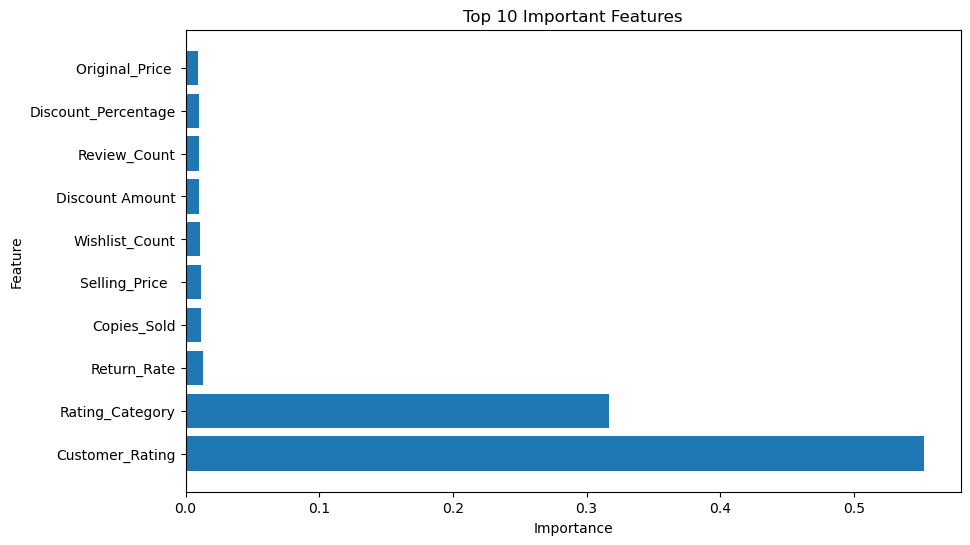

In [22]:
plt.figure(figsize=(10,6))

plt.barh(
    importance['Feature'][:10],
    importance['Importance'][:10]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Important Features")

plt.show()

In [27]:
df.to_csv("ML Project Task 4.csv", index=False)

print("Dataset Saved Successfully!")

Dataset Saved Successfully!
